In [2]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from operator import itemgetter
from torch.utils.data import DataLoader, TensorDataset, Dataset
import torch.optim as optim
import torch.optim.lr_scheduler as lr_scheduler
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import r2_score
import flwr as fl

from collections import OrderedDict
from typing import Dict, List, Optional, Tuple


In [3]:
BATCH_SIZE=32
NUM_CLIENTS=10
num_rounds=50
num_epochs=50

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(DEVICE)

cuda


In [4]:
df = pd.read_csv("/home/ushtro/Documents/AIML/fed_l/ML-Aided-NR-V2X-QoS-Predictions/dataset.csv")
df.head()

,Unnamed: 0,X,Y,throughput,mcs,distance,pktsize,delay,jitter,sinr,power,dlpathloss,pdr
0,0,146.601387,368.116530,1.743593,13,184.225706,190,3.242855,0.000000,-1.38581,15,-95.2246,99
1,1,143.260663,365.862937,1.743592,13,188.238131,190,6.579737,1.241554,-3.11075,15,-95.3060,99
2,2,137.782258,362.167301,1.743593,13,194.819602,190,3.242855,0.000000,-1.24068,15,-95.5003,99
3,3,131.346059,357.825556,1.743592,13,202.553954,190,6.579767,1.241449,-3.51258,15,-95.8110,99
4,4,128.942275,355.120683,1.742541,13,206.124022,190,9.782037,1.008803,-3.02864,15,-96.1639,99


In [5]:
df.shape

(8941, 13)

In [6]:
print(df.isnull().sum().sum())

3241


In [7]:
df.dropna(inplace=True)

In [8]:
print(df.shape)
print(df.isnull().sum().sum())

(5700, 13)
0


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5700 entries, 0 to 8940
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  5700 non-null   int64  
 1   X           5700 non-null   float64
 2   Y           5700 non-null   float64
 3   throughput  5700 non-null   float64
 4   mcs         5700 non-null   int64  
 5   distance    5700 non-null   float64
 6   pktsize     5700 non-null   int64  
 7   delay       5700 non-null   float64
 8   jitter      5700 non-null   float64
 9   sinr        5700 non-null   float64
 10  power       5700 non-null   int64  
 11  dlpathloss  5700 non-null   float64
 12  pdr         5700 non-null   int64  
dtypes: float64(8), int64(5)
memory usage: 623.4 KB


In [10]:
features = ["distance", "pktsize" , "jitter", "sinr" ,"throughput", "pdr"]
print(len(features))
target1 = "throughput"
target2 = "pdr"

6


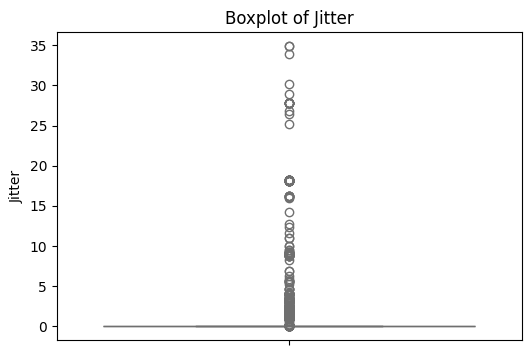

In [11]:
plt.figure(figsize=(6, 4))
sns.boxplot(y=df["jitter"], color="skyblue")

# Add labels and title
plt.ylabel("Jitter")
plt.title("Boxplot of Jitter")

# Show the plot
plt.show()

In [12]:
# from sklearn.preprocessing import MinMaxScaler
# scaler = MinMaxScaler()
# df[features] = scaler.fit_transform(df[features])

In [13]:
class NR_V2X(Dataset):
    def __init__(self, df, features, target, seq_length=25):
        self.features = df[features].values
        self.target = df[target].values
        self.seq_length = seq_length

    def __len__(self):
        return len(self.features) - self.seq_length  

    def __getitem__(self, idx):
        X = self.features[idx: idx + self.seq_length]
        y = self.target[idx + self.seq_length] 
        return torch.tensor(X, dtype=torch.float32), torch.tensor(y, dtype=torch.float32)

In [14]:
def load_dataset(df, features, target, num_clients: int):
    client_size = df.shape[0] // num_clients
    datasets = []
    targets = []
    scalers = []  # Store scalers for each client
    
    j = 0
    for i in range(num_clients):
        client_df = df.iloc[j : j + client_size].reset_index(drop=True)
        
        # Apply MinMaxScaler separately for each client
        scaler = MinMaxScaler()
        scaled_data = scaler.fit_transform(client_df)
        scaled_df = pd.DataFrame(scaled_data, columns=df.columns)
        
        datasets.append(scaled_df)
        scalers.append(scaler)
        j += client_size

    # Train-test split
    train_data = []
    test_data = []
    train_size = int(client_size * 0.8)

    for i in range(num_clients):
        train_data.append(datasets[i].iloc[:train_size])
        test_data.append(datasets[i].iloc[train_size:])
        
        # Extract target column correctly
        targets.append(test_data[i][target].values)  

    # Create DataLoaders
    train_loaders = []
    test_loaders = []
    for i in range(num_clients):
        train_dataset = NR_V2X(train_data[i], features, target)
        test_dataset = NR_V2X(test_data[i], features, target)
        
        train_loaders.append(DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=False))
        test_loaders.append(DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False))

    return train_loaders, test_loaders, targets, scalers


In [15]:
trainloaders, testloaders, targets, scalers = load_dataset(df, features, target1, NUM_CLIENTS)

In [16]:
for i, train_loader in enumerate(trainloaders):
    print(f"Client {i+1} Train Loader Size: {len(train_loader)} batches")

for i, test_loader in enumerate(testloaders):
    print(f"Client {i+1} Test Loader Size: {len(test_loader)} batches")

for i in range(NUM_CLIENTS):
    print(len(targets[i]))
    break

Client 1 Train Loader Size: 14 batches
Client 2 Train Loader Size: 14 batches
Client 3 Train Loader Size: 14 batches
Client 4 Train Loader Size: 14 batches
Client 5 Train Loader Size: 14 batches
Client 6 Train Loader Size: 14 batches
Client 7 Train Loader Size: 14 batches
Client 8 Train Loader Size: 14 batches
Client 9 Train Loader Size: 14 batches
Client 10 Train Loader Size: 14 batches
Client 1 Test Loader Size: 3 batches
Client 2 Test Loader Size: 3 batches
Client 3 Test Loader Size: 3 batches
Client 4 Test Loader Size: 3 batches
Client 5 Test Loader Size: 3 batches
Client 6 Test Loader Size: 3 batches
Client 7 Test Loader Size: 3 batches
Client 8 Test Loader Size: 3 batches
Client 9 Test Loader Size: 3 batches
Client 10 Test Loader Size: 3 batches
114


In [17]:
def get_parameters(net) -> List[np.ndarray]:
    return [val.cpu().numpy() for _, val in net.state_dict().items()]


def set_parameters(net, parameters: List[np.ndarray]):
    params_dict = zip(net.state_dict().keys(), parameters)
    state_dict = OrderedDict({k: torch.from_numpy(v) for k, v in params_dict})
    net.load_state_dict(state_dict, strict=True)


In [18]:
class LSTM(nn.Module):
    def __init__(self):
        super(LSTM, self).__init__()
        self.input_size = 6
        self.output_size = 1
        self.hidden_size = 50
        self.num_layers = 3
        
        self.lstm = nn.LSTM(self.input_size, self.hidden_size, self.num_layers, batch_first=True)
        
        self.fc = nn.Linear(self.hidden_size, self.output_size)

    def forward(self, x):
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(x.device)
        c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(x.device)

        out, _ = self.lstm(x, (h0, c0)) 
        
        out = self.fc(out[:, -1, :]) 
        
        return out

In [19]:
def train(model, trainloader, epochs):
    lr=0.001
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    scheduler = lr_scheduler.LinearLR(optimizer, start_factor=1.0, end_factor=0.1, total_iters=epochs)
    model.train()
    e = []
    
    for epoch in range(epochs):
        total, epoch_loss = 0,0
        e.append(epoch+1)
        for X, y in trainloader:
            X, y = X.to(DEVICE), y.to(DEVICE)
            
            optimizer.zero_grad()
            pred = model(X)
            loss = criterion(pred.squeeze(), y)
            loss.backward()
            optimizer.step()

            total += X.size(0)
            epoch_loss += loss.item()

        scheduler.step()

        if (epoch+1)%5==0:
            print(f"Epoch {epoch+1}: train loss: {epoch_loss}")

In [20]:
def test(model, testloader, target):
    model.eval()
    predicted_y = []
    target_list = [] 
    criterion = nn.MSELoss()
    loss_total = 0

    with torch.no_grad():
        for X, y in testloader:
            X, y = X.to(DEVICE), y.to(DEVICE)
            target_list.extend(y.cpu().numpy().flatten()) 
            pred = model(X)
            loss = criterion(pred, y)
            pred_cpu = pred.cpu().numpy().flatten()  
            predicted_y.extend(pred_cpu.tolist()) 
            loss_total += loss.item()

    r2 = r2_score(target_list, predicted_y)
    return r2, loss_total

In [21]:
class FlowerClient(fl.client.NumPyClient):
    def __init__(self, cid, model, trainloader, testloader, target, scaler):
        self.cid = int(cid)
        self.model = model
        self.trainloader = trainloader
        self.testloader = testloader
        self.target = target
        self.scaler = scaler
        self.destination = "output"

    def get_parameters(self, config):
        print(f"[Client {self.cid} get_parameters]")
        return get_parameters(self.model)

    def fit(self, parameters, config):
        server_round = config["server_round"]
        local_epochs = config["local_epochs"]

        print(f"[Client {self.cid}, round {server_round}] fit, config:{config}")
        set_parameters(self.model, parameters)
        train(self.model, self.trainloader, epochs=local_epochs)
        return get_parameters(self.model), len(self.trainloader), {}

    def evaluate(self, parameters, config):
        print(f"[Client {self.cid}] evaluate, config: {config}")
        server_round = config["server_round"]
        set_parameters(self.model, parameters)

        r2_score, test_loss = test(self.model, self.testloader, self.target)
        print(f"Client {self.cid} R² Score: {r2_score}, Loss: {test_loss}")

        # Ensure output directory exists
        output_dir = os.path.join("/kaggle/working/", "r2_scores")
        os.makedirs(output_dir, exist_ok=True)

        # Save evaluation metrics
        file_path = os.path.join(output_dir, f"server_round_{server_round}.txt")
        with open(file_path, "a") as file:
            file.write(f"client {self.cid} {float(r2_score)} \n")

        if server_round == num_rounds:
            self.model.eval()
            with torch.no_grad():
                predictions = []
                for x in self.testloader:
                    x = x.to(DEVICE)
                    outputs = self.model(x).cpu().numpy().astype("float64")
                    predictions.extend(outputs)

            pred_test = np.array(predictions).reshape(-1)
            pred_test_df = pd.DataFrame(pred_test, columns=["pred_test"])
            pred_test_df = pd.concat([pred_test_df] * 5, axis=1)

            # Inverse transform predictions
            pred_test_unscaled = self.scaler.inverse_transform(pred_test_df.to_numpy())[:, 4]
            np.save(os.path.join(output_dir, f"predictions_client_{self.cid}.npy"), pred_test_unscaled)

            predicted_df = pd.DataFrame(pred_test_unscaled, columns=["pred_test"])

            # Process actual test values
            scaled_testY = np.concatenate([batch.numpy() for batch in self.testloader], axis=0)
            actual_df = pd.DataFrame(scaled_testY, columns=["actual"])
            actual_df = pd.concat([actual_df] * 5, axis=1)

            actual_unscaled = self.scaler.inverse_transform(actual_df.to_numpy())[:, 4]
            np.save(os.path.join(output_dir, f"actual_client_{self.cid}.npy"), actual_unscaled)

            actual_df_final = pd.DataFrame(actual_unscaled, columns=["actual"])

            # Save CSV
            combined_df = pd.concat([actual_df_final, predicted_df], axis=1)
            combined_csv_path = os.path.join(output_dir, f"combined_client_{self.cid}.csv")
            combined_df.to_csv(combined_csv_path, index=False)

            # Plot & Save Figure
            plt.figure(figsize=(10, 7))
            plt.plot(actual_df_final["actual"], color="blue", linewidth=2, label="ACTUAL")
            plt.plot(predicted_df["pred_test"], color="red", linewidth=2, label="PREDICTED")
            plt.legend(fontsize=22, loc="lower right")
            plt.ylabel("Throughput", fontsize=22, fontweight="bold")
            plt.xlabel("Time", fontsize=22, fontweight="bold")
            plt.yticks(fontsize=22, fontweight="bold")
            plt.xticks(fontsize=22, fontweight="bold")
            plt.title("Actual & Predicted Throughput vs Time", fontsize=22, fontweight="bold")
            plt.grid()
            plt.tight_layout()

            figure_path = os.path.join(output_dir, f"Actual_and_Predicted_client_{self.cid}.jpg")
            plt.savefig(figure_path)

        return float(r2_score), len(self.testloader), {"loss per sample": float(test_loss)}


In [22]:
def client_fn(cid) -> FlowerClient:
    model = LSTM().to(DEVICE)
    global trainloaders
    global testloaders
    trainloader = trainloaders[int(cid)]
    testloader = testloaders[int(cid)]
    target = targets[int(cid)]
    scaler = scalers[int(cid)]
    flower_client = FlowerClient(cid, model, trainloader, testloader, target, scaler)
    return flower_client.to_client()

In [23]:
model = LSTM()
model.to(DEVICE)

LSTM(
  (lstm): LSTM(6, 50, num_layers=3, batch_first=True)
  (fc): Linear(in_features=50, out_features=1, bias=True)
)

In [24]:
params = get_parameters(model.to(DEVICE))
# print(params)
# train(model, trainloaders[0], 5)
del model

In [25]:
def evaluate(
    server_round: int,
    params: fl.common.NDArrays,
    config: Dict[str, fl.common.Scalar],
) -> Optional[Tuple[float, Dict[str, fl.common.Scalar]]]:
    model = LSTM().to(DEVICE)
    testloader = testloaders[0]
    set_parameters(model, params)
    R2, total_loss = test(model, testloader, targets[0])
    print(f"Server-side R2 score is {R2} and validation loss is {total_loss}")
    return total_loss,{"R2": R2}

In [26]:
def fit_config(server_round: int):
    """Return training configuration dict for each round.

    Perform two rounds of training with one local epoch, increase to two local
    epochs afterwards.
    """
    config = {
        "server_round": server_round,  # The current round of federated learning
        "local_epochs": num_epochs
    }
    return config

In [27]:
strategy = fl.server.strategy.FedAvg(
    fraction_fit=0.7,
    fraction_evaluate=1,
    min_fit_clients=7,
    min_evaluate_clients=NUM_CLIENTS,
    min_available_clients=NUM_CLIENTS,
    initial_parameters=fl.common.ndarrays_to_parameters(params),
    evaluate_fn=evaluate,
    on_fit_config_fn=fit_config,
    on_evaluate_config_fn=fit_config
)


In [28]:
client_resources = {"num_cpus":1,"num_gpus":1}

In [ ]:
Output_History=fl.simulation.start_simulation(
    client_fn=client_fn,
    num_clients=NUM_CLIENTS,
    config=fl.server.ServerConfig(num_rounds=num_rounds),
    strategy=strategy,
    client_resources=client_resources
)

	Instead, use the `flwr run` CLI command to start a local simulation in your Flower app, as shown for example below:

		$ flwr new  # Create a new Flower app from a template

		$ flwr run  # Run the Flower app in Simulation Mode

	Using `start_simulation()` is deprecated.

            This is a deprecated feature. It will be removed
            entirely in future versions of Flower.
        
INFO :      Starting Flower simulation, config: num_rounds=50, no round_timeout
2025-05-25 02:27:30,786	INFO worker.py:1771 -- Started a local Ray instance.
INFO :      Flower VCE: Ray initialized with resources: {'accelerator_type:G': 1.0, 'node:__internal_head__': 1.0, 'CPU': 16.0, 'object_store_memory': 3369854976.0, 'node:172.20.10.4': 1.0, 'memory': 6739709952.0, 'GPU': 1.0}
INFO :      Optimize your simulation with Flower VCE: https://flower.ai/docs/framework/how-to-run-simulations.html
INFO :      Flower VCE: Resources for each Virtual Client: {'num_cpus': 1, 'num_gpus': 1}
INFO :      Flowe

Server-side R2 score is -0.1049773059111736 and validation loss is 0.17414561100304127


(ClientAppActor pid=13901) WARNING :   DEPRECATED FEATURE: `client_fn` now expects a signature `def client_fn(context: Context)`.The provided `client_fn` has signature: {'cid': <Parameter "cid">}. You can import the `Context` like this: `from flwr.common import Context`
(ClientAppActor pid=13901) 
(ClientAppActor pid=13901)             This is a deprecated feature. It will be removed
(ClientAppActor pid=13901)             entirely in future versions of Flower.
(ClientAppActor pid=13901)         


(ClientAppActor pid=13901) [Client 1, round 1] fit, config:{'server_round': 1, 'local_epochs': 50}
(ClientAppActor pid=13901) Epoch 5: train loss: 0.5085499790293397
(ClientAppActor pid=13901) Epoch 10: train loss: 0.21072532776815933
(ClientAppActor pid=13901) Epoch 15: train loss: 0.1872549712570617
(ClientAppActor pid=13901) Epoch 20: train loss: 0.1615745850140229
(ClientAppActor pid=13901) Epoch 25: train loss: 0.14893177391058998
(ClientAppActor pid=13901) Epoch 30: train loss: 0.13477548438095255
(ClientAppActor pid=13901) Epoch 35: train loss: 0.12845475368158077
(ClientAppActor pid=13901) Epoch 40: train loss: 0.12125595884572249
(ClientAppActor pid=13901) Epoch 45: train loss: 0.11670727115415502
(ClientAppActor pid=13901) Epoch 50: train loss: 0.11336173546442296
(ClientAppActor pid=13901) [Client 3, round 1] fit, config:{'server_round': 1, 'local_epochs': 50}


(ClientAppActor pid=13901) WARNING :   DEPRECATED FEATURE: `client_fn` now expects a signature `def client_fn(context: Context)`.The provided `client_fn` has signature: {'cid': <Parameter "cid">}. You can import the `Context` like this: `from flwr.common import Context`
(ClientAppActor pid=13901) 
(ClientAppActor pid=13901)             This is a deprecated feature. It will be removed
(ClientAppActor pid=13901)             entirely in future versions of Flower.
(ClientAppActor pid=13901)         


...

(ClientAppActor pid=13901) Epoch 5: train loss: 0.05622995083103888
(ClientAppActor pid=13901) Epoch 10: train loss: 0.028043057831382612
(ClientAppActor pid=13901) Epoch 15: train loss: 0.03848366597594577
(ClientAppActor pid=13901) Epoch 20: train loss: 0.07832133619922388
(ClientAppActor pid=13901) Epoch 25: train loss: 0.019981259437827248
(ClientAppActor pid=13901) Epoch 30: train loss: 0.013473729206452845
(ClientAppActor pid=13901) Epoch 35: train loss: 0.011857396273626364
(ClientAppActor pid=13901) Epoch 40: train loss: 0.011160986641243653
(ClientAppActor pid=13901) Epoch 45: train loss: 0.010807157975250448
(ClientAppActor pid=13901) Epoch 50: train loss: 0.010618280261496693


(ClientAppActor pid=13901) WARNING :   DEPRECATED FEATURE: `client_fn` now expects a signature `def client_fn(context: Context)`.The provided `client_fn` has signature: {'cid': <Parameter "cid">}. You can import the `Context` like this: `from flwr.common import Context`
(ClientAppActor pid=13901) 
(ClientAppActor pid=13901)             This is a deprecated feature. It will be removed
(ClientAppActor pid=13901)             entirely in future versions of Flower.
(ClientAppActor pid=13901)         


(ClientAppActor pid=13901) [Client 4, round 2] fit, config:{'server_round': 2, 'local_epochs': 50}
(ClientAppActor pid=13901) Epoch 5: train loss: 0.33230173841729993
(ClientAppActor pid=13901) Epoch 10: train loss: 0.3109016172820702
(ClientAppActor pid=13901) Epoch 15: train loss: 0.278209745309141
(ClientAppActor pid=13901) Epoch 20: train loss: 0.26607854905887507
(ClientAppActor pid=13901) Epoch 25: train loss: 0.2604720562012517
(ClientAppActor pid=13901) Epoch 30: train loss: 0.2528438421431929
(ClientAppActor pid=13901) Epoch 35: train loss: 0.24621548430877738
(ClientAppActor pid=13901) Epoch 40: train loss: 0.24047891314330627
(ClientAppActor pid=13901) Epoch 45: train loss: 0.23571644858384388
(ClientAppActor pid=13901) Epoch 50: train loss: 0.2320698174953577
(ClientAppActor pid=13901) [Client 0, round 2] fit, config:{'server_round': 2, 'local_epochs': 50}


(ClientAppActor pid=13901) WARNING :   DEPRECATED FEATURE: `client_fn` now expects a signature `def client_fn(context: Context)`.The provided `client_fn` has signature: {'cid': <Parameter "cid">}. You can import the `Context` like this: `from flwr.common import Context`
(ClientAppActor pid=13901) 
(ClientAppActor pid=13901)             This is a deprecated feature. It will be removed
(ClientAppActor pid=13901)             entirely in future versions of Flower.
(ClientAppActor pid=13901)         


(ClientAppActor pid=13901) Epoch 5: train loss: 0.3004135896335356
(ClientAppActor pid=13901) Epoch 10: train loss: 0.24203264582320116
(ClientAppActor pid=13901) Epoch 15: train loss: 0.22649842864484526
(ClientAppActor pid=13901) Epoch 20: train loss: 0.20435212492884602
(ClientAppActor pid=13901) Epoch 25: train loss: 0.18659718315757345
(ClientAppActor pid=13901) Epoch 30: train loss: 0.18902408733265474
